# 01 Xiong QC: mouse healthy vs NASH (GSE129516)

Raw counts → quality control → doublet removal → cell-type labels → `processed/xiong_qc.h5ad`.

Modeled on the Leone Lab `DataProcessing.ipynb`, with one difference: GEO ships **filtered**
matrices (cells already called by the authors), so there is no barcode-rank knee step.
Each file is a genes × cells CSV for one mouse: chow1–3 are healthy, nash1–3 are NASH.

**Plain-language QC:** we drop droplets that look broken (too few genes), droplets that
likely hold two cells (too many genes, or flagged by Scrublet), and dying cells (a high share
of mitochondrial reads).

In [1]:
import os, gzip
import numpy as np
import pandas as pd
import scipy.sparse as sp
import anndata as ad
import scanpy as sc
import matplotlib.pyplot as plt
from config import *
from lcm import *

sc.settings.verbosity = 1
sc.settings.set_figure_params(dpi=80, facecolor="white")
FIG = os.path.join("figures", "01_xiong"); os.makedirs(FIG, exist_ok=True)
CUT = QC["xiong"]
samples = XIONG if DEV_SUBSET is None else XIONG[:DEV_SUBSET]
print("samples:", [s for _, s, _ in samples], "| cutoffs:", CUT)

samples: ['chow1', 'chow2', 'chow3', 'nash1', 'nash2', 'nash3'] | cutoffs: {'min_genes': 500, 'max_genes': 6000, 'max_pct_mt': 10}


## 1. Load
The CSVs are dense (every zero written out), so each file is read in row chunks and turned
into a sparse matrix as it goes. This keeps memory low, in the same spirit as the Leone Lab
streaming loader.

In [2]:
def read_dense_csv(path, chunk=2000):
    with gzip.open(path, "rt") as f:
        cells = f.readline().rstrip("\n").split(",")[1:]
    cells = [c.strip('"') for c in cells]
    genes, blocks = [], []
    for df in pd.read_csv(path, index_col=0, chunksize=chunk):
        genes.extend(df.index)
        blocks.append(sp.csr_matrix(df.to_numpy(dtype=np.float32)))
    X = sp.vstack(blocks).T.tocsr()          # genes x cells -> cells x genes
    return X, cells, genes

parts = []
for gsm, sample, condition in samples:
    X, cells, genes = read_dense_csv(os.path.join(RAW, "GSE129516", XIONG_FILE.format(gsm=gsm, sample=sample)))
    assert X.shape == (len(cells), len(genes))
    assert "Alb" in genes and "Sox17" in genes, "rows should be gene symbols"
    a = ad.AnnData(X=X, obs=pd.DataFrame(index=[f"xiong_{sample}_{c}" for c in cells]), var=pd.DataFrame(index=genes))
    a.obs["dataset"], a.obs["species"], a.obs["sample"] = "xiong", "mouse", sample
    a.obs["donor"], a.obs["condition"] = f"mouse_{sample}", condition
    parts.append(a)
    print(f"{sample}: {a.n_obs:,} cells x {a.n_vars:,} genes")

adata = ad.concat(parts, join="outer", fill_value=0)
del parts
adata.var_names_make_unique()
for c in ["dataset", "species", "sample", "donor", "condition"]:
    adata.obs[c] = adata.obs[c].astype("category")
sc.pp.filter_genes(adata, min_cells=MIN_CELLS)
print(adata); ram("after load")

chow1: 4,058 cells x 19,349 genes


chow2: 8,119 cells x 19,349 genes


chow3: 5,611 cells x 19,349 genes


nash1: 6,475 cells x 19,349 genes


nash2: 3,577 cells x 19,349 genes


nash3: 5,328 cells x 19,349 genes


AnnData object with n_obs × n_vars = 33168 × 19327
    obs: 'dataset', 'species', 'sample', 'donor', 'condition'
    var: 'n_cells'
[RAM] after load process uses 0.4 GB


0.380485632

## 2. Quality control
The authors already removed cells with ≤ 500 genes, so the lower cut barely bites. We add a
mitochondrial cap and an upper gene cap, as in Leone Lab. **Check the percentiles below
before trusting the cutoffs in `config.py`.**

{'mt': 13, 'ribo': 113, 'hb': 4} genes flagged


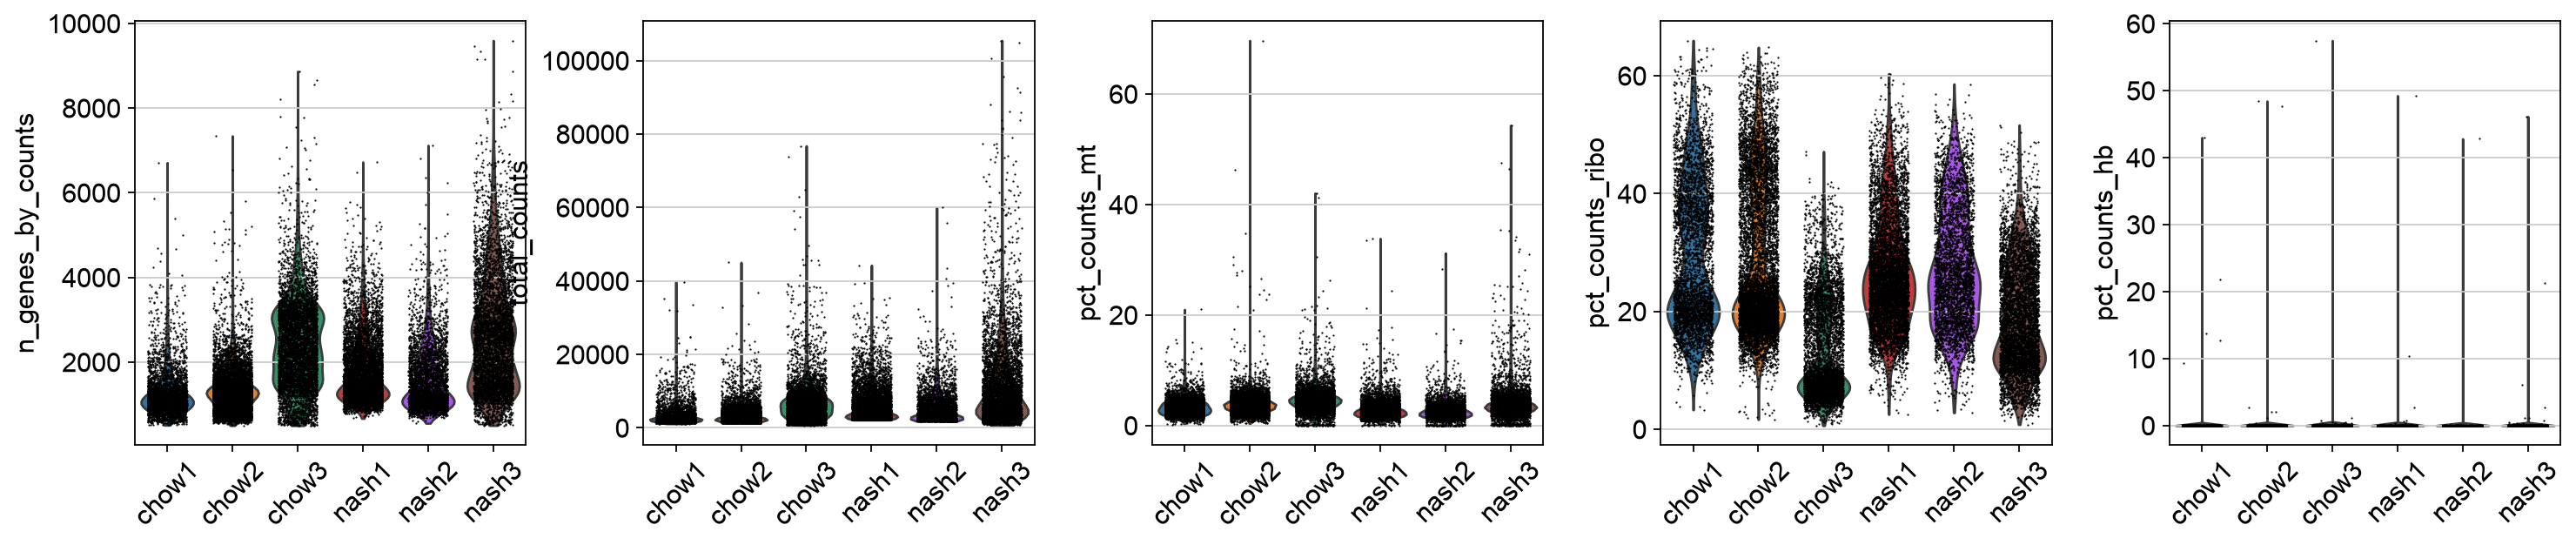

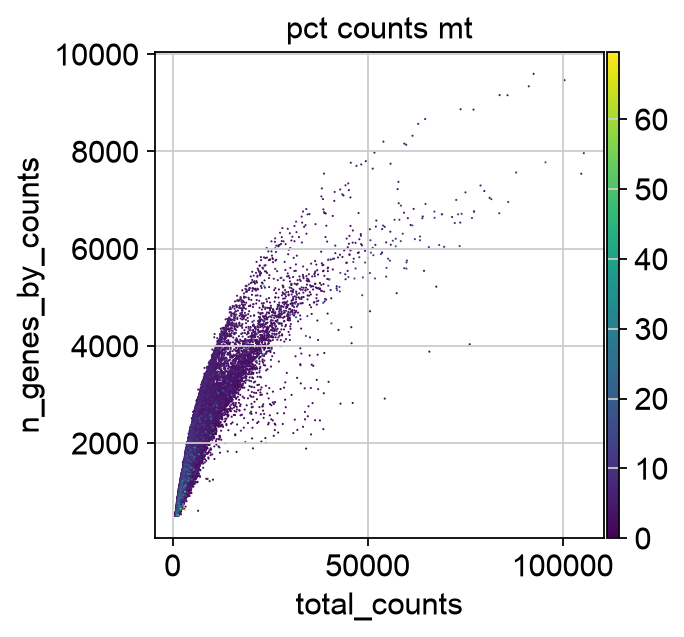

In [3]:
add_qc_metrics(adata, "mouse")
sc.pl.violin(adata, QC_COLS, groupby="sample", multi_panel=False, jitter=0.3, rotation=45, show=False)
plt.savefig(os.path.join(FIG, "qc_violins_before.png"), bbox_inches="tight"); plt.show()
sc.pl.scatter(adata, x="total_counts", y="n_genes_by_counts", color="pct_counts_mt", show=False)
plt.savefig(os.path.join(FIG, "qc_scatter_before.png"), bbox_inches="tight"); plt.show()

In [4]:
qc_diagnostics(adata, CUT)

           metric     p1     p5    p25    p50    p75     p95     p99
n_genes_by_counts  609.0  765.0 1132.0 1483.0 2294.2  3813.0  5263.0
     total_counts 1195.0 1600.4 2447.0 3705.0 7114.0 17308.7 32483.4
    pct_counts_mt    0.3    1.3    2.4    3.4    4.4     6.6    11.2
  pct_counts_ribo    4.2    6.6   15.8   22.0   31.2    46.9    55.1
    pct_counts_hb    0.0    0.0    0.0    0.0    0.0     0.0     0.1

< 500 genes: 0 | >= 6000 genes: 156 | >= 10% mito: 452 | removed by any: 584 of 33,168


In [5]:
before_qc = adata.obs[["sample"]].copy()
adata = apply_qc(adata, CUT)
print(f"cells after QC cutoffs: {adata.n_obs:,}")

cells after QC cutoffs: 32,584


## 3. Doublets (Scrublet, per mouse)

In [6]:
after_qc = adata.obs[["sample"]].copy()
adata = remove_doublets(adata)
print(f"cells after doublet removal: {adata.n_obs:,}"); ram("after scrublet")

sample
chow1    0.001
chow2    0.001
chow3    0.004
nash1    0.000
nash2    0.000
nash3    0.001


cells after doublet removal: 32,536
[RAM] after scrublet process uses 1.5 GB


1.524137984

In [7]:
counts = pd.DataFrame({"loaded": before_qc["sample"].value_counts(), "after QC": after_qc["sample"].value_counts(),
                       "after doublets": adata.obs["sample"].value_counts()})
counts.loc["total"] = counts.sum()
counts.to_csv(os.path.join(FIG, "cells_per_sample.csv")); counts

,loaded,after QC,after doublets
sample,,,
chow2,8119,8067,8055
nash1,6475,6429,6426
chow3,5611,5449,5428
nash3,5328,5058,5052
chow1,4058,4031,4026
nash2,3577,3550,3549
total,33168,32584,32536


## 4. Cell-type labels (CellTypist `Healthy_Mouse_Liver`, majority voting)
Labels come from a model trained on healthy mouse liver, so disease-specific states (like
NASH macrophages) get the nearest healthy label. That is expected; 04 checks for them by markers.

In [8]:
labels = celltypist_labels(adata, "Healthy_Mouse_Liver.pkl")
adata.obs = adata.obs.join(labels)
adata.obs["celltype_native"].value_counts()

/opt/anaconda3/envs/scrnaseq/lib/python3.11/site-packages/celltypist/classifier.py:11: FutureWarning: `__version__` is deprecated, use `importlib.metadata.version('scanpy')` instead
  from scanpy import __version__ as scv
📂 Storing models in /Users/xinqing/.celltypist/data/models


💾 Total models to download: 1


⏩ Skipping [1/1]: Healthy_Mouse_Liver.pkl (file exists)


/opt/anaconda3/envs/scrnaseq/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


🔬 Input data has 32536 cells and 19327 genes


🔗 Matching reference genes in the model


... (5 outputs left out)

⛓️ Over-clustering input data with resolution set to 15


🗳️ Majority voting the predictions


✅ Majority voting done!


celltype_native
Endothelial cells                     10412
T cells                                6278
Monocytes & Monocyte-derived cells     3999
Kupffer cells                          3852
B cells                                3762
cDC2s                                   810
Cholangiocytes                          737
Hepatocytes                             599
cDC1s                                   505
pDCs                                    403
ILC1s                                   388
Fibroblasts                             366
NK cells                                316
Mig. cDCs                               109
Name: count, dtype: int64

In [9]:
pd.crosstab(adata.obs["celltype_native"], adata.obs["condition"])

condition,disease,healthy
celltype_native,,
B cells,1244,2518
Cholangiocytes,352,385
Endothelial cells,2501,7911
Fibroblasts,156,210
Hepatocytes,401,198
ILC1s,267,121
Kupffer cells,2487,1365
Mig. cDCs,79,30
Monocytes & Monocyte-derived cells,3379,620


## 5. Save
`.X` keeps **raw integer counts** (normalization happens after merging in 03).

In [10]:
adata.X = adata.X.astype(np.float32)
safe_write(adata, os.path.join(PROCESSED, "xiong_qc.h5ad"))

... storing 'sample' as categorical


... storing 'donor' as categorical


... storing 'condition' as categorical


wrote /Volumes/Crystal Hard Drive/CSE6242_data/processed/xiong_qc.h5ad | 32,536 cells x 19,327 genes | 0.14 GB
